<a href="https://colab.research.google.com/github/FinnLuetzen/KI-Vorlesung/blob/main/linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dense, Normalization
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

In [ ]:
url = 'http://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data'
column_names = ['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'Model Year', 'Origin']

raw_dataset = pd.read_csv(url, names=column_names, na_values='?', comment='\t', sep=' ', skipinitialspace=True)
display(raw_dataset)
dataset = raw_dataset.copy()
dataset = dataset.dropna()
dataset['Origin'] = dataset['Origin'].map({1: 'USA', 2: 'Europe', 3: 'Japan'})
dataset = pd.get_dummies(dataset, columns=['Origin'], prefix='', prefix_sep='')

for col in ['USA', 'Europe', 'Japan']:
    dataset[col] = dataset[col].astype(int)

dataset.tail()

train_dataset = dataset.sample(frac=0.8, random_state=0)
test_dataset = dataset.drop(train_dataset.index)

train_features = train_dataset.copy()
test_features = test_dataset.copy()

train_labels = train_features.pop('MPG')
test_labels = test_features.pop('MPG')
test_results = {}

normalizer = Normalization(axis=-1)
normalizer.adapt(np.array(train_features))
horsepower = np.array(train_features['Horsepower'])
horsepower_normalizer = Normalization(input_shape=[1,], axis=None)
horsepower_normalizer.adapt(horsepower)

def plot_loss(history, subplot_rows, subplot_columns, subplot_place):
    plt.subplot(subplot_rows, subplot_columns, subplot_place)
    plt.title("Training history")
    plt.plot(history.history['loss'], label='loss')
    plt.plot(history.history['val_loss'], label='val_loss')
    plt.xlabel('Epoch')
    plt.ylabel('Error [MPG]')
    plt.ylim([0, 10])
    plt.legend()
    plt.grid(True)

def plot_horsepower_predictions(x, y, subplot_rows, subplot_columns, subplot_place):
    plt.subplot(subplot_rows, subplot_columns, subplot_place)
    plt.title("Predictions over real data")
    plt.scatter(train_features['Horsepower'], train_labels, label='Data')
    plt.plot(x, y, color='k', label='Predictions')
    plt.xlabel('Horsepower')
    plt.ylabel('MPG')
    plt.legend()

def plot_predictions(test_predictions, test_labels, subplot_rows, subplot_columns, subplot_place):
    plt.subplot(subplot_rows, subplot_columns, subplot_place)
    plt.title("Model predictions vs. real test labels")
    plt.scatter(test_labels, test_predictions)
    plt.xlabel('True Values [MPG]')
    plt.ylabel('Predictions [MPG]')
    lims = [0, 50]
    plt.xlim(lims)
    plt.ylim(lims)
    plt.plot(lims, lims, color='lightblue')

def error_distribution(test_predictions, test_labels, subplot_rows, subplot_columns, subplot_place):
    error = test_predictions - test_labels

    plt.subplot(subplot_rows, subplot_columns, subplot_place)
    plt.title("Error distribution")
    plt.hist(error, bins=25)
    plt.xlabel('Prediction Error [MPG]')
    plt.ylabel('Count')

display(train_features)

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
0,18.0,8,307.0,130.0,3504.0,12.0,70,1
1,15.0,8,350.0,165.0,3693.0,11.5,70,1
2,18.0,8,318.0,150.0,3436.0,11.0,70,1
3,16.0,8,304.0,150.0,3433.0,12.0,70,1
4,17.0,8,302.0,140.0,3449.0,10.5,70,1
...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790.0,15.6,82,1
394,44.0,4,97.0,52.0,2130.0,24.6,82,2
395,32.0,4,135.0,84.0,2295.0,11.6,82,1
396,28.0,4,120.0,79.0,2625.0,18.6,82,1


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Europe,Japan,USA
146,4,90.0,75.0,2125.0,14.5,74,0,0,1
282,4,140.0,88.0,2890.0,17.3,79,0,0,1
69,8,350.0,160.0,4456.0,13.5,72,0,0,1
378,4,105.0,63.0,2125.0,14.7,82,0,0,1
331,4,97.0,67.0,2145.0,18.0,80,0,1,0
...,...,...,...,...,...,...,...,...,...
281,6,200.0,85.0,2990.0,18.2,79,0,0,1
229,8,400.0,180.0,4220.0,11.1,77,0,0,1
150,4,108.0,93.0,2391.0,15.5,74,0,1,0
145,4,83.0,61.0,2003.0,19.0,74,0,1,0


The user should edit this function ([Documentation](https://github.com/Totemi1324/neural-networks-demo/blob/main/examples/regression.md)):

In [ ]:
def build_and_compile_model(norm):
  model = Sequential([
    norm,
    Dense(100, activation='relu'),
    Dense(12, activation='relu'),
    Dense(1, activation='relu'),
    Dense(1)
  ])

  learning_rate = 0.001

  model.compile(loss='mean_absolute_error',
                optimizer=Adam(learning_rate))
  return model

Training only on horsepower:

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 1)              │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 304 (1.19 KB)

 Trainable params: 301 (1.18 KB)

 Non-trainable params: 3 (16.00 B)

The model is training, please wait...
Finished! Printing results
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


,Mean absolute error [MPG]
dnn_horsepower_model,3.072187


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


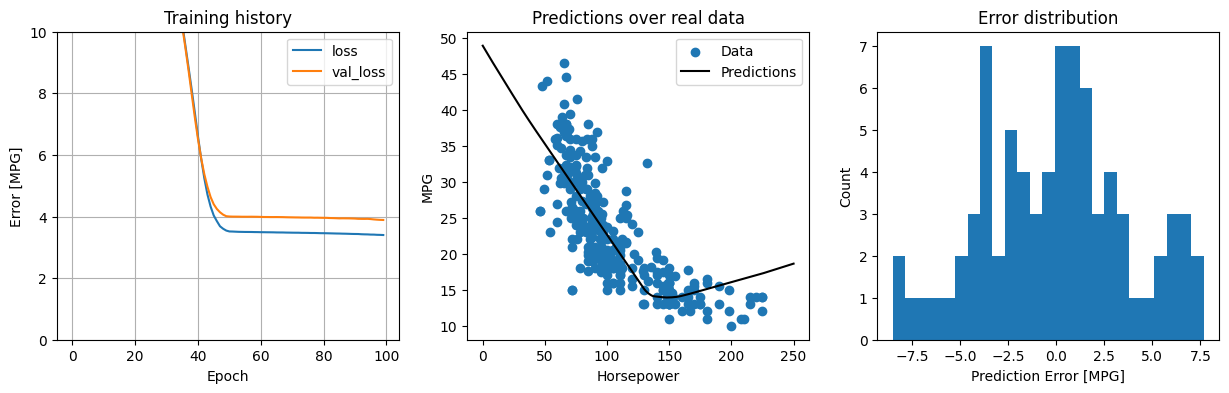

In [ ]:
dnn_horsepower_model = build_and_compile_model(horsepower_normalizer)
dnn_horsepower_model.summary()

print("The model is training, please wait...")
history = dnn_horsepower_model.fit(
    train_features['Horsepower'],
    train_labels,
    validation_split=0.2,
    verbose=0, epochs=100)
print("Finished! Printing results");

x = tf.linspace(0.0, 250, 251)
y = dnn_horsepower_model.predict(x)

test_results = {}
test_results['dnn_horsepower_model'] = dnn_horsepower_model.evaluate(test_features['Horsepower'], test_labels, verbose=0)
display(pd.DataFrame(test_results, index=['Mean absolute error [MPG]']).T)

fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(15)

plot_loss(history, 1, 3, 1)
test_predictions = dnn_horsepower_model.predict(test_features['Horsepower'].values).flatten()
plot_horsepower_predictions(x, y, 1, 3, 2)
error_distribution(test_predictions, test_labels, 1, 3, 3)

plt.show()

Training on all features:

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19 (80.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 19 (80.00 B)

The model is training, please wait...
Finished! Printing results


,Mean absolute error [MPG]
dnn_horsepower_model,3.072187
dnn_model,5.280250


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


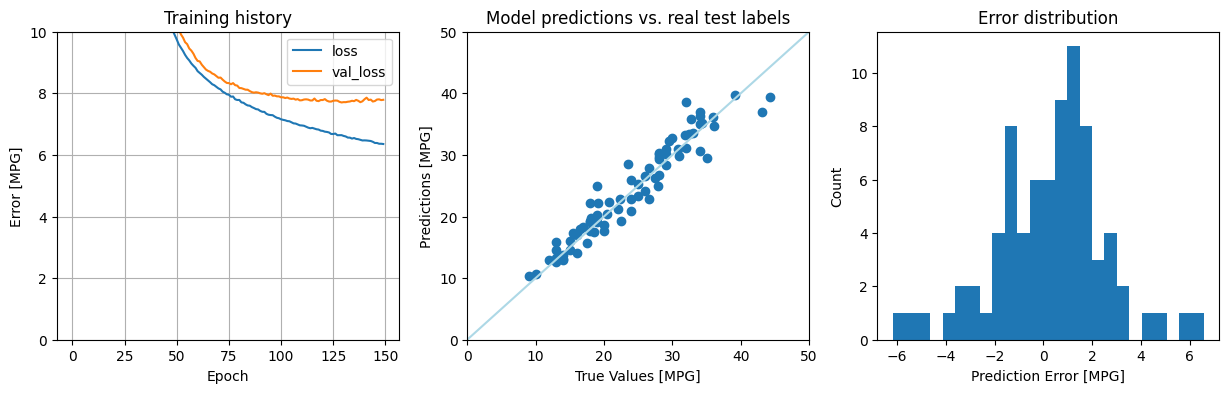

In [ ]:
dnn_model = build_and_compile_model(normalizer)
dnn_model.summary()

print("The model is training, please wait...")
history = dnn_model.fit(
    train_features,
    train_labels,
    validation_split=0.2,
    verbose=0, epochs=150)
print("Finished! Printing results");

test_results['dnn_model'] = dnn_model.evaluate(test_features, test_labels, verbose=0)
display(pd.DataFrame(test_results, index=['Mean absolute error [MPG]']).T)

fig = plt.figure()
fig.set_figheight(4)
fig.set_figwidth(15)

plot_loss(history, 1, 3, 1)
test_predictions = dnn_model.predict(test_features).flatten()
plot_predictions(test_predictions, test_labels, 1, 3, 2)
error_distribution(test_predictions, test_labels, 1, 3, 3)

plt.show()